# Практические занятия Листок 5. Дискретные случайные величины и их числовые характеристики. Независимость.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, factorial, sqrt
from fractions import Fraction
import sympy as sp
from scipy.stats import poisson
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

### **5.1** Дискретная СВ X принимает целые значения 1,…,6 (равновероятно). Y_n — остаток от деления X на n (n=2 или 3). Верно ли, что Y_2 и Y_3 независимы? Та же задача для P(X=k) = A·k. Найти ковариацию между Y_2 и Y_3.


In [3]:
values = [1, 2, 3, 4, 5, 6]
y2 = [x % 2 for x in values]
y3 = [x % 3 for x in values]

# 1 Равномерное распределение P(X=k) = 1/6
p_uniform = [sp.Rational(1, 6)] * 6

def check_independence(y2_vals, y3_vals, probs):
    # Совместное распределение (Y_2, Y_3)
    joint = {}
    for v2, v3, p in zip(y2_vals, y3_vals, probs):
        key = (v2, v3)
        joint[key] = joint.get(key, 0) + p
    # Маргиналы
    p_y2 = {}
    p_y3 = {}
    for (v2, v3), p in joint.items():
        p_y2[v2] = p_y2.get(v2, 0) + p
        p_y3[v3] = p_y3.get(v3, 0) + p
    independent = True
    for (v2, v3), p in joint.items():
        if abs(float(p) - float(p_y2[v2] * p_y3[v3])) > 1e-12:
            independent = False
            break
    return joint, p_y2, p_y3, independent

joint, p_y2, p_y3, ind = check_independence(y2, y3, p_uniform)
print('Случай 1: P(X=k) = 1/6')
print(f'Совместное распределение (Y_2, Y_3): {joint}')
print(f'P(Y_2): {p_y2}')
print(f'P(Y_3): {p_y3}')
print(f'Независимы? {ind}')

# Ковариация
E_y2 = sum(v2 * p for v2, p in p_y2.items())
E_y3 = sum(v3 * p for v3, p in p_y3.items())
E_y2y3 = sum(v2 * v3 * p for (v2, v3), p in joint.items())
cov1 = E_y2y3 - E_y2 * E_y3
print(f'Cov(Y_2, Y_3) = {cov1}')

# 2 P(X=k) = A*k, A = 2/(6*7) = 1/21
A = sp.Rational(2, 42)
p_prop = [A * k for k in values]
joint2, p_y2_2, p_y3_2, ind2 = check_independence(y2, y3, p_prop)
print('\nСлучай 2: P(X=k) = A*k, A = 1/21')
print(f'Совместное распределение (Y_2, Y_3): {joint2}')
print(f'P(Y_2): {p_y2_2}')
print(f'P(Y_3): {p_y3_2}')
print(f'Независимы? {ind2}')

E_y2_2 = sum(v2 * p for v2, p in p_y2_2.items())
E_y3_2 = sum(v3 * p for v3, p in p_y3_2.items())
E_y2y3_2 = sum(v2 * v3 * p for (v2, v3), p in joint2.items())
cov2 = E_y2y3_2 - E_y2_2 * E_y3_2
print(f'E[Y_2] = {E_y2_2}, E[Y_3] = {E_y3_2}, E[Y_2*Y_3] = {E_y2y3_2}')
print(f'Cov(Y_2, Y_3) = {cov2} = {float(cov2):.6f}')


Случай 1: P(X=k) = 1/6
Совместное распределение (Y_2, Y_3): {(1, 1): 1/6, (0, 2): 1/6, (1, 0): 1/6, (0, 1): 1/6, (1, 2): 1/6, (0, 0): 1/6}
P(Y_2): {1: 1/2, 0: 1/2}
P(Y_3): {1: 1/3, 2: 1/3, 0: 1/3}
Независимы? True
Cov(Y_2, Y_3) = 0

Случай 2: P(X=k) = A*k, A = 1/21
Совместное распределение (Y_2, Y_3): {(1, 1): 1/21, (0, 2): 2/21, (1, 0): 1/7, (0, 1): 4/21, (1, 2): 5/21, (0, 0): 2/7}
P(Y_2): {1: 3/7, 0: 4/7}
P(Y_3): {1: 5/21, 2: 1/3, 0: 3/7}
Независимы? False
E[Y_2] = 3/7, E[Y_3] = 19/21, E[Y_2*Y_3] = 11/21
Cov(Y_2, Y_3) = 20/147 = 0.136054


### **5.2** Независимые X (0…12, p=1/13), Y (0…13, p=1/14), Z∈{3,7}, P(Z=3)=9/10. Найти: a) P(X+Y+Z=12); б) наиболее вероятное значение суммы X+Y+Z и его вероятность; в) распределение.


a) P(X+Y+Z=12) = 24/455 = 0.0527472527
б) M = 16, P(X+Y+Z=M) = 127/1820 = 0.0697802198

в) Распределение X+Y+Z:
  P(S= 3) = 0.004945
  P(S= 4) = 0.009890
  P(S= 5) = 0.014835
  P(S= 6) = 0.019780
  P(S= 7) = 0.025275
  P(S= 8) = 0.030769
  P(S= 9) = 0.036264
  P(S=10) = 0.041758
  P(S=11) = 0.047253
  P(S=12) = 0.052747
  P(S=13) = 0.058242
  P(S=14) = 0.063736
  P(S=15) = 0.069231
  P(S=16) = 0.069780
  P(S=17) = 0.065385
  P(S=18) = 0.060989
  P(S=19) = 0.056593
  P(S=20) = 0.051648
  P(S=21) = 0.046154
  P(S=22) = 0.040659
  P(S=23) = 0.035165
  P(S=24) = 0.029670
  P(S=25) = 0.024176
  P(S=26) = 0.018681
  P(S=27) = 0.013187
  P(S=28) = 0.007692
  P(S=29) = 0.002198
  P(S=30) = 0.001648
  P(S=31) = 0.001099
  P(S=32) = 0.000549


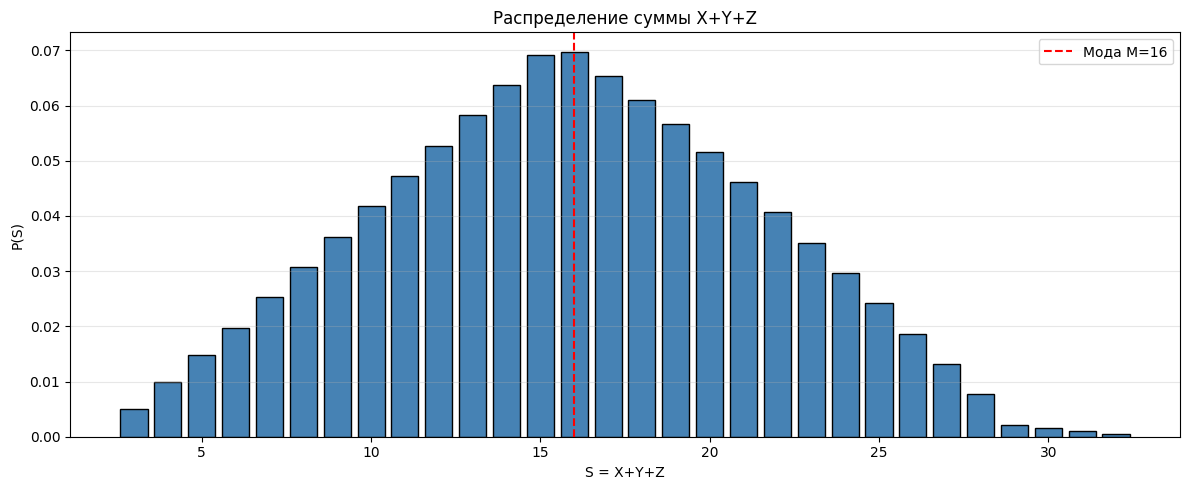

In [4]:
from collections import defaultdict

# Распределения
pX = {i: sp.Rational(1, 13) for i in range(13)}
pY = {j: sp.Rational(1, 14) for j in range(14)}
pZ = {3: sp.Rational(9, 10), 7: sp.Rational(1, 10)}

# Совместное распределение X+Y+Z
dist = defaultdict(lambda: sp.Rational(0))
for x, px in pX.items():
    for y, py in pY.items():
        for z, pz in pZ.items():
            dist[x + y + z] += px * py * pz

# a) P(X+Y+Z = 12)
P_12 = dist[12]
print(f'a) P(X+Y+Z=12) = {P_12} = {float(P_12):.10f}')

# б) наиболее вероятное значение
M = max(dist, key=lambda k: dist[k])
print(f'б) M = {M}, P(X+Y+Z=M) = {dist[M]} = {float(dist[M]):.10f}')

# в) распределение
print('\nв) Распределение X+Y+Z:')
ks = sorted(dist.keys())
for k in ks:
    print(f'  P(S={k:2d}) = {float(dist[k]):.6f}')

# График распределения
plt.figure(figsize=(12, 5))
plt.bar(ks, [float(dist[k]) for k in ks], color='steelblue', edgecolor='black')
plt.axvline(x=M, color='red', ls='--', label=f'Мода M={M}')
plt.xlabel('S = X+Y+Z'); plt.ylabel('P(S)')
plt.title('Распределение суммы X+Y+Z')
plt.legend(); plt.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()


### **5.3** X (1…13, P=A·i), Y (1…12, P=B·j), Z (1…8, P=C·k) — независимые. Найти P(X≠Y, X≠Z, Y≠Z).


In [5]:
# A = 2/(13*14), B = 2/(12*13), C = 2/(8*9)
A = sp.Rational(2, 13*14)
B = sp.Rational(2, 12*13)
C = sp.Rational(2, 8*9)

pX = {i: A * i for i in range(1, 14)}
pY = {j: B * j for j in range(1, 13)}
pZ = {k: C * k for k in range(1, 9)}

P_diff = sp.Rational(0)
for x, px in pX.items():
    for y, py in pY.items():
        if y == x:
            continue
        for z, pz in pZ.items():
            if z == x or z == y:
                continue
            P_diff += px * py * pz

print(f'5.3 P(X не равен Y, X не равен Z, Y не равен Z) = {P_diff} = {float(P_diff):.10f}')

# Моделирование
N = 500000
xs = np.random.choice(range(1, 14), size=N, p=[float(pX[i]) for i in range(1, 14)])
ys = np.random.choice(range(1, 13), size=N, p=[float(pY[j]) for j in range(1, 13)])
zs = np.random.choice(range(1, 9), size=N, p=[float(pZ[k]) for k in range(1, 9)])
p_sim = np.mean((xs != ys) & (xs != zs) & (ys != zs))
print(f'Моделирование: P_hat = {p_sim:.6f}')


5.3 P(X не равен Y, X не равен Z, Y не равен Z) = 16687/21294 = 0.7836479760
Моделирование: P_hat = 0.783926


### **5.4** 4 игральные кости. X = min. Найти E(X), Var(X), Cov(одна кость, min). Разыграть эксперимент.


E(X) = 2275/1296 = 1.7554
Var(X) = 1528583/1679616 = 0.910079
E[X_1*min] = 6.702932
Cov(X_1, min) = 161/288 = 0.559028

Моделирование: E_hat[min] = 1.7547, Var_hat(min) = 0.910590
Моделирование: Cov_hat(X_1, min) = 0.556759


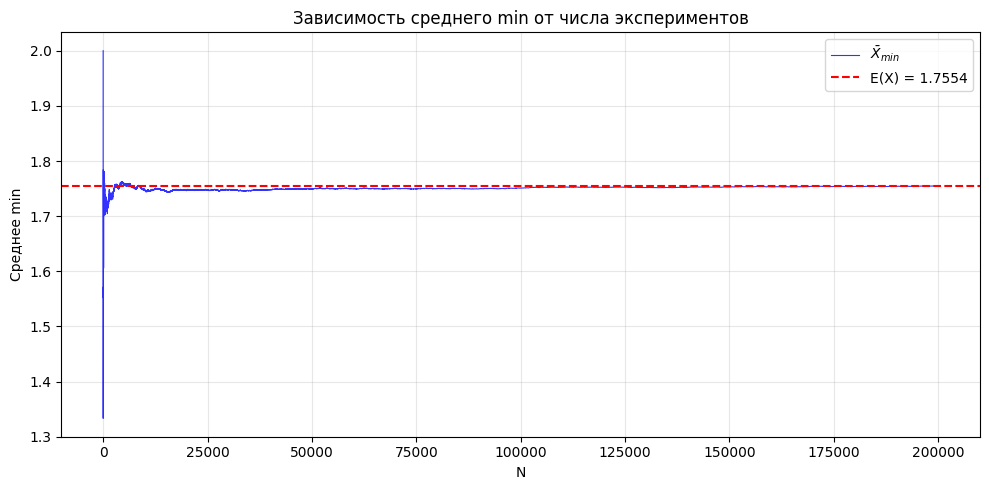

In [6]:
p_min = {k: sp.Rational(7-k, 6)**4 - sp.Rational(7-(k+1), 6)**4 for k in range(1, 7)}
E_X = sum(k * p_min[k] for k in range(1, 7))
E_X2 = sum(k**2 * p_min[k] for k in range(1, 7))
Var_X = E_X2 - E_X**2
print(f'E(X) = {E_X} = {float(E_X):.4f}')
print(f'Var(X) = {Var_X} = {float(Var_X):.6f}')

E_X1 = sp.Rational(7, 2)
E_X1_min = sp.Rational(0)
for x in range(1, 7):
    for m in range(1, x + 1):
        if m == x:
            p = sp.Rational(1, 6) * sp.Rational(7 - x, 6)**3
        else:  # m < x
            p_min3_m = sp.Rational(7 - m, 6)**3 - sp.Rational(7 - (m + 1), 6)**3
            p = sp.Rational(1, 6) * p_min3_m
        E_X1_min += x * m * p
cov = E_X1_min - E_X1 * E_X
print(f'E[X_1*min] = {float(E_X1_min):.6f}')
print(f'Cov(X_1, min) = {cov} = {float(cov):.6f}')

# Моделирование
N = 200000
rolls = np.random.randint(1, 7, size=(N, 4))
mins = np.min(rolls, axis=1)
print(f'\nМоделирование: E_hat[min] = {mins.mean():.4f}, Var_hat(min) = {mins.var():.6f}')
print(f'Моделирование: Cov_hat(X_1, min) = {np.cov(rolls[:, 0], mins)[0, 1]:.6f}')

# График зависимости среднего от числа экспериментов
cum_mean = np.cumsum(mins) / np.arange(1, N + 1)
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, N + 1), cum_mean, 'b-', lw=0.8, alpha=0.8, label=r'$\bar{X}_{min}$')
plt.axhline(y=float(E_X), color='r', ls='--', label=f'E(X) = {float(E_X):.4f}')
plt.xlabel('N'); plt.ylabel('Среднее min')
plt.title('Зависимость среднего min от числа экспериментов')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### **5.5** 4 игральные кости. X = max. Найти E(X), Var(X). Разыграть эксперимент.


E(X) =  5.2446
Var(X) = 0.910079
Моделирование: E_hat[max] = 5.2450, Var_hat(max) = 0.910460


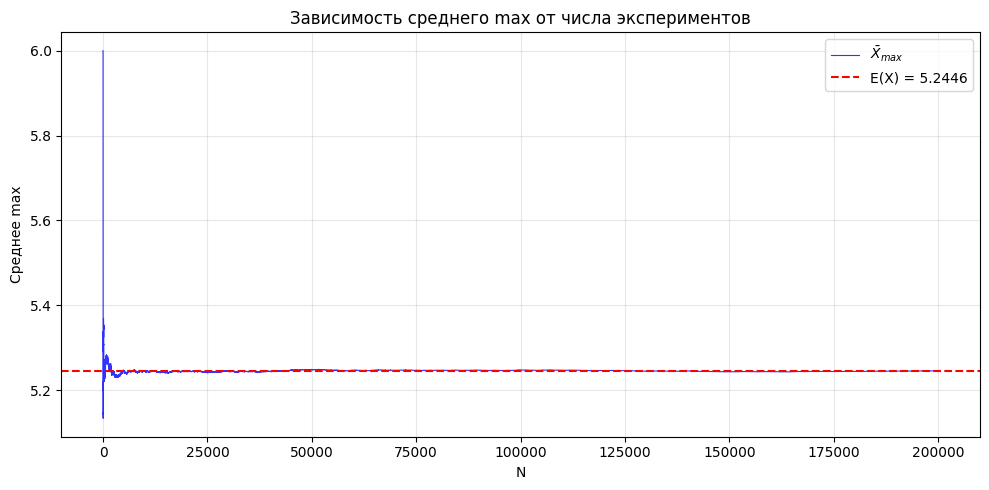

In [7]:
p_max = {k: sp.Rational(k, 6)**4 - sp.Rational(k - 1, 6)**4 for k in range(1, 7)}
E_X = sum(k * p_max[k] for k in range(1, 7))
E_X2 = sum(k**2 * p_max[k] for k in range(1, 7))
Var_X = E_X2 - E_X**2
print(f'E(X) =  {float(E_X):.4f}')
print(f'Var(X) = {float(Var_X):.6f}')

# Моделирование
N = 200000
rolls = np.random.randint(1, 7, size=(N, 4))
maxs = np.max(rolls, axis=1)
print(f'Моделирование: E_hat[max] = {maxs.mean():.4f}, Var_hat(max) = {maxs.var():.6f}')

cum_mean = np.cumsum(maxs) / np.arange(1, N + 1)
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, N + 1), cum_mean, 'b-', lw=0.8, alpha=0.8, label=r'$\bar{X}_{max}$')
plt.axhline(y=float(E_X), color='r', ls='--', label=f'E(X) = {float(E_X):.4f}')
plt.xlabel('N'); plt.ylabel('Среднее max')
plt.title('Зависимость среднего max от числа экспериментов')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### **5.6** 4 игральные кости. S = сумма наибольших трёх выпавших очков. Найти E(S). Разыграть эксперимент.


E(S) = 4*3.5 − E[min] = 12.2446
Моделирование: E_hat[S] = 12.2471


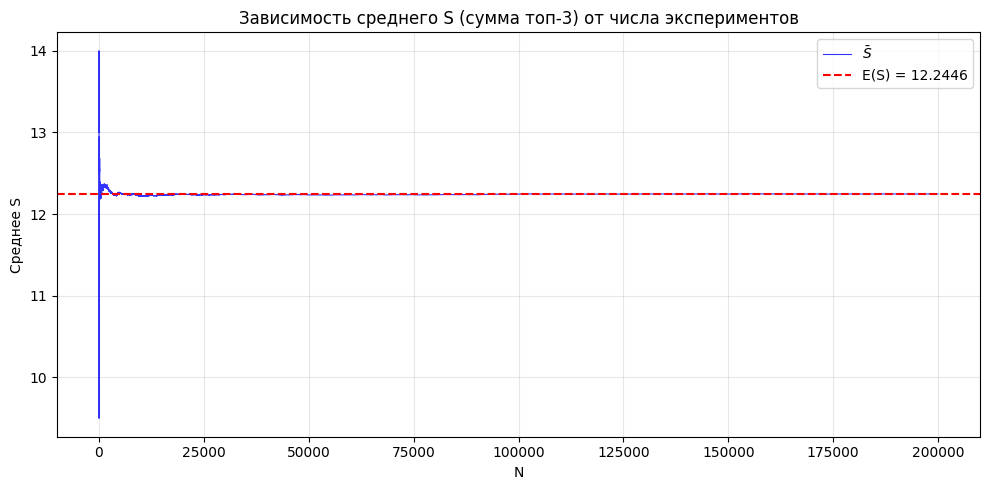

In [8]:
# S = (сумма всех 4) − min
# E[S] = 4*E[кость] − E[min] = 4*3.5 − E[min]
E_min = sp.Rational(227, 1296)
# Точное значение E[min] для 4 костей
p_min = {k: sp.Rational(7-k, 6)**4 - sp.Rational(7-(k+1), 6)**4 for k in range(1, 7)}
E_min_exact = sum(k * p_min[k] for k in range(1, 7))
E_S = 4 * sp.Rational(7, 2) - E_min_exact
print(f'E(S) = 4*3.5 − E[min] = {float(E_S):.4f}')

# Моделирование
N = 200000
rolls = np.random.randint(1, 7, size=(N, 4))
S = np.sum(rolls, axis=1) - np.min(rolls, axis=1)
print(f'Моделирование: E_hat[S] = {S.mean():.4f}')

cum_mean = np.cumsum(S) / np.arange(1, N + 1)
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, N + 1), cum_mean, 'b-', lw=0.8, alpha=0.8, label=r'$\bar{S}$')
plt.axhline(y=float(E_S), color='r', ls='--', label=f'E(S) = {float(E_S):.4f}')
plt.xlabel('N'); plt.ylabel('Среднее S')
plt.title('Зависимость среднего S (сумма топ-3) от числа экспериментов')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### **5.7** A, B, C — попарно независимы, P(A)=0.4, P(B)=0.3, P(C)=0.2, P(ABC)=0. X=1_A, Y=1_B, Z=1_C, V=2X+4Y+6Z. Найти E(V), Var(V).


In [9]:
# E[V] = 2*E[X] + 4*E[Y] + 6*E[Z] = 2*0.4 + 4*0.3 + 6*0.2
E_V = 2*0.4 + 4*0.3 + 6*0.2
print(f'1) E(V) = {E_V}')

# Попарная независимость -> все Cov = 0
Var_X = 0.4 * 0.6
Var_Y = 0.3 * 0.7
Var_Z = 0.2 * 0.8
Var_V = 4*Var_X + 16*Var_Y + 36*Var_Z
print(f'2) Var(V) = {Var_V}')

# Моделирование
N = 500000
A = np.random.random(N) < 0.4
B = np.random.random(N) < 0.3
C = np.random.random(N) < 0.2
V = 2*A + 4*B + 6*C
print(f'Моделирование: E_hat[V] = {V.mean():.4f}, Var_hat(V) = {V.var():.4f}')


1) E(V) = 3.2
2) Var(V) = 10.080000000000002
Моделирование: E_hat[V] = 3.2000, Var_hat(V) = 10.0578


### **5.8** X — равномерно на {1,…,64}. Y = |X − 13.5|. Найти квартили.


In [10]:
xs = np.arange(1, 65)
ys = np.abs(xs - 13.5)

sorted_y = np.sort(ys)

def Q1Min(y):
    # Наименьшее q с P(Y <= q) >= 0.25
    for q in sorted_y:
        if np.mean(y <= q) >= 0.25:
            return q

def Q1Max(y):
    # Наибольшее q с P(Y >= q) >= 0.75
    for q in sorted_y[::-1]:
        if np.mean(y >= q) >= 0.75:
            return q

def Q3Min(y):
    for q in sorted_y:
        if np.mean(y <= q) >= 0.75:
            return q

def Q3Max(y):
    for q in sorted_y[::-1]:
        if np.mean(y >= q) >= 0.25:
            return q

print(f'1) Q1Min = {Q1Min(ys)}')
print(f'2) Q1Max = {Q1Max(ys)}')
print(f'3) Q3Min = {Q3Min(ys)}')
print(f'4) Q3Max = {Q3Max(ys)}')

# Моделирование
N = 500000
X = np.random.randint(1, 65, size=N)
Y = np.abs(X - 13.5)
print(f'\nМоделирование (N={N}):')
print(f'Q1Min = {Q1Min(Y)}, Q1Max = {Q1Max(Y)}, Q3Min = {Q3Min(Y)}, Q3Max = {Q3Max(Y)}')


1) Q1Min = 7.5
2) Q1Max = 8.5
3) Q3Min = 34.5
4) Q3Max = 35.5

Моделирование (N=500000):
Q1Min = 7.5, Q1Max = 7.5, Q3Min = 35.5, Q3Max = 35.5


### **5.9** Квадрат 100, треугольник 42, круг 58, пересечение 24. 5 случайных точек. X_i, Y_i — индикаторы, Z_i = X_i + Y_i. U = ΣZ_i, V = ΠZ_i. Найти E(U), Var(U), E(V), Var(V).


In [11]:
P_T = 42 / 100  # P(треугольник)
P_C = 58 / 100  # P(круг)
P_TC = 24 / 100  # P(пересечение)

P_Z0 = 1 - (P_T + P_C - P_TC)
P_Z1 = (P_T - P_TC) + (P_C - P_TC)
P_Z2 = P_TC
print(f'P(Z=0) = {P_Z0}, P(Z=1) = {P_Z1}, P(Z=2) = {P_Z2}')

E_Z = 0*P_Z0 + 1*P_Z1 + 2*P_Z2
E_Z2 = 0*P_Z0 + 1*P_Z1 + 4*P_Z2
Var_Z = E_Z2 - E_Z**2
print(f'E[Z] = {E_Z}, Var(Z) = {Var_Z}')

E_U = 5 * E_Z
Var_U = 5 * Var_Z
print(f'1) E(U) = {E_U}')
print(f'2) Var(U) = {Var_U}')

E_V = E_Z ** 5
E_V2 = E_Z2 ** 5
Var_V = E_V2 - E_V**2
print(f'3) E(V) = {E_V}')
print(f'4) Var(V) = {Var_V}')

# Моделирование
N = 300000
Z = np.random.choice([0, 1, 2], size=(N, 5), p=[P_Z0, P_Z1, P_Z2])
U = Z.sum(axis=1)
V = Z.prod(axis=1)
print(f'\nМоделирование: E_hat[U] = {U.mean():.4f}, Var_hat(U) = {U.var():.4f}')
print(f'Моделирование: E_hat[V] = {V.mean():.4f}, Var_hat(V) = {V.var():.4f}')


P(Z=0) = 0.24, P(Z=1) = 0.52, P(Z=2) = 0.24
E[Z] = 1.0, Var(Z) = 0.48
1) E(U) = 5.0
2) Var(U) = 2.4
3) E(V) = 1.0
4) Var(V) = 6.100821196799999

Моделирование: E_hat[U] = 4.9979, Var_hat(U) = 2.3997
Моделирование: E_hat[V] = 0.9988, Var_hat(V) = 6.1161


### **5.10** X_i ∈ {2,5,8,10} (равновероятно), S = X_1+X_2+X_3. Найти E(S), MedMin, MedMax, ModMin, ModMax.


1) E(S) = 18.75
2) MedMin = 18
3) MedMax = 20
4) ModMin = 20
5) ModMax = 20
P(S=20) = 0.140625


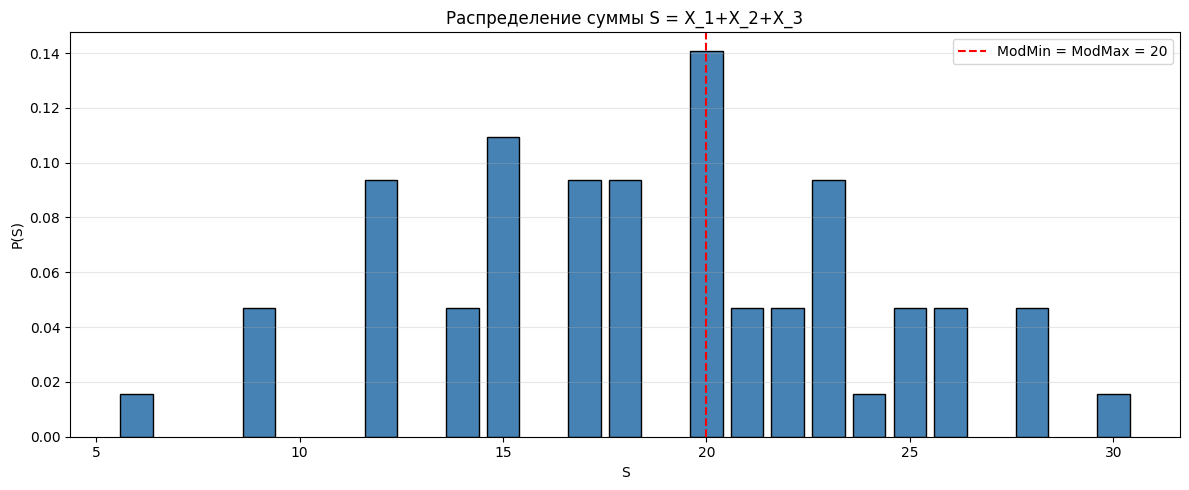

In [12]:
vals = [2, 5, 8, 10]
probs = [0.25, 0.25, 0.25, 0.25]

# Распределение S = X1+X2+X3
from itertools import product as iprod
dist = {}
for combo in iprod(vals, repeat=3):
    s = sum(combo)
    dist[s] = dist.get(s, 0) + (0.25**3)

# 1) E(S)
E_S = sum(s * p for s, p in dist.items())
print(f'1) E(S) = {E_S}')

# Сортируем возможные значения S
sorted_s = sorted(dist.keys())
cdf = []
cum = 0
for s in sorted_s:
    cum += dist[s]
    cdf.append(cum)

# 2) MedMin
MedMin = next(s for s, c in zip(sorted_s, cdf) if c >= 0.5)
print(f'2) MedMin = {MedMin}')

# 3) MedMax
MedMax = None
for s in sorted_s[::-1]:
    if sum(dist[k] for k in sorted_s if k >= s) >= 0.5:
        MedMax = s
        break
print(f'3) MedMax = {MedMax}')

# 4) ModMin - наименьшее значение с максимальной вероятностью
# 5) ModMax - наибольшее значение с максимальной вероятностью
max_p = max(dist.values())
modes = sorted([s for s, p in dist.items() if abs(p - max_p) < 1e-12])
ModMin, ModMax = modes[0], modes[-1]
print(f'4) ModMin = {ModMin}')
print(f'5) ModMax = {ModMax}')
print(f'P(S={ModMin}) = {dist[ModMin]}')

# График распределения S
plt.figure(figsize=(12, 5))
plt.bar(sorted_s, [dist[s] for s in sorted_s], color='steelblue', edgecolor='black')
plt.axvline(x=ModMin, color='red', ls='--', label=f'ModMin = ModMax = {ModMin}')
plt.xlabel('S'); plt.ylabel('P(S)')
plt.title('Распределение суммы S = X_1+X_2+X_3')
plt.legend(); plt.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()


### **5.11** Цена акции: +4% (p=0.1), +0.3% (p=0.5), −1% (p=0.4). S_0=1000. Найти E(S_160) и σ(S_160).


In [13]:
# Относительное изменение R: +0.04, +0.003, −0.01
R_vals = np.array([0.04, 0.003, -0.01])
R_probs = np.array([0.1, 0.5, 0.4])

E_factor = np.sum((1 + R_vals) * R_probs)  # E[1+R]
E_factor2 = np.sum((1 + R_vals)**2 * R_probs)  # E[(1+R)^2]
Var_factor = E_factor2 - E_factor**2

S0 = 1000
E_S160 = S0 * E_factor**160
Var_S160 = S0**2 * E_factor2**160 - E_S160**2
std_S160 = np.sqrt(Var_S160)

print(f'1) E(S_160) = {E_S160:.3f}')
print(f'2) σ(S_160) = {std_S160:.3f}')

# Моделирование
N = 50000
factors = np.random.choice(1 + R_vals, size=(N, 160), p=R_probs)
S160 = S0 * np.prod(factors, axis=1)
print(f'\nМоделирование: E_hat[S_160] = {S160.mean():.3f}, sigma_hat = {S160.std():.3f}')


1) E(S_160) = 1271.021
2) σ(S_160) = 230.142

Моделирование: E_hat[S_160] = 1270.271, sigma_hat = 231.000


### **5.12** Портфель из A и B. E_A=4%, σ_A=5%, E_B=5%, σ_B=8%, ρ_AB=0.26. Найти доли в портфеле минимальной дисперсии, его доходность и σ.


1) Доля A = 0.786, Доля B = 0.214
2) E(портфеля) = 4.21%, σ = 4.68%


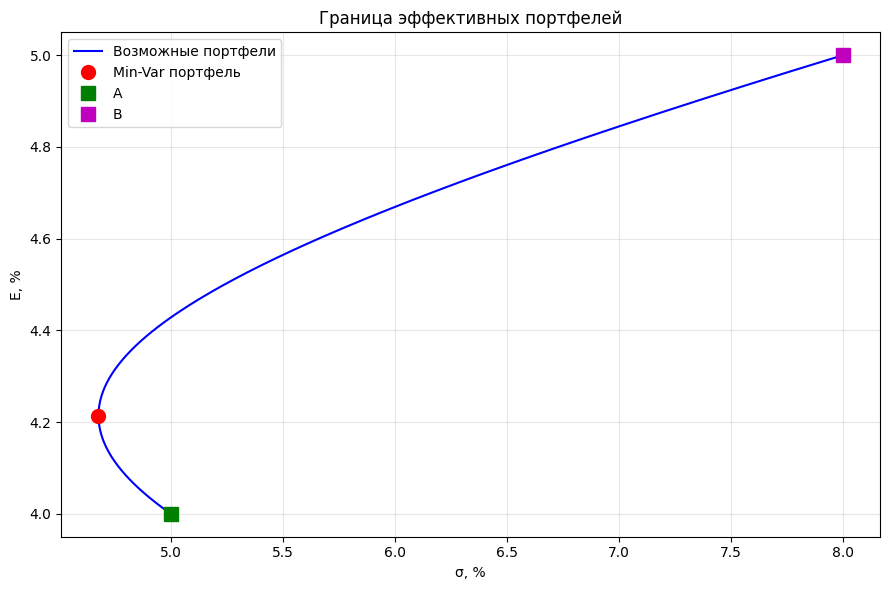

In [14]:
# Минимальная дисперсия
E_A, E_B = 0.04, 0.05
sA, sB = 0.05, 0.08
rho = 0.26
cov_AB = rho * sA * sB

w_A = (sB**2 - cov_AB) / (sA**2 + sB**2 - 2*cov_AB)
w_B = 1 - w_A
E_P = w_A * E_A + w_B * E_B
var_P = w_A**2 * sA**2 + w_B**2 * sB**2 + 2 * w_A * w_B * cov_AB
s_P = np.sqrt(var_P)

print(f'1) Доля A = {w_A:.3f}, Доля B = {w_B:.3f}')
print(f'2) E(портфеля) = {E_P*100:.2f}%, σ = {s_P*100:.2f}%')

# График границы эффективных портфелей
ws = np.linspace(0, 1, 200)
Es = ws * E_A + (1 - ws) * E_B
sigmas = np.sqrt(ws**2 * sA**2 + (1-ws)**2 * sB**2 + 2*ws*(1-ws)*cov_AB)
plt.figure(figsize=(9, 6))
plt.plot(sigmas*100, Es*100, 'b-', label='Возможные портфели')
plt.plot(s_P*100, E_P*100, 'ro', ms=10, label=f'Min-Var портфель')
plt.plot(sA*100, E_A*100, 'gs', ms=10, label='A')
plt.plot(sB*100, E_B*100, 'ms', ms=10, label='B')
plt.xlabel('σ, %'); plt.ylabel('E, %')
plt.title('Граница эффективных портфелей')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### **5.13** A, B, C — независимы. E=(1,3,3)%, σ=(2,6,5)%. Найти ожидаемую доходность портфеля минимальной дисперсии.


In [15]:
Es = np.array([0.01, 0.03, 0.03])
sigmas = np.array([0.02, 0.06, 0.05])

# Минимизация
inv_var = 1 / sigmas**2
w = inv_var / inv_var.sum()
E_P = np.dot(w, Es)
var_P = np.dot(w**2, sigmas**2)
s_P = np.sqrt(var_P)

print(f'Доли: w_A={w[0]:.4f}, w_B={w[1]:.4f}, w_C={w[2]:.4f}')
print(f'E(портфеля) = {E_P*100:.3f}%')
print(f'σ(портфеля) = {s_P*100:.3f}%')


Доли: w_A=0.7867, w_B=0.0874, w_C=0.1259
E(портфеля) = 1.427%
σ(портфеля) = 1.774%


### **5.14** Портфель 7:1 (A:B). E_A=3%, E_B=2%, σ_A=σ_B=4%, ρ=0.3. Найти σ портфеля.


In [16]:
# Доли (w_A = 7/8, w_B = 1/8)
w_A, w_B = 7/8, 1/8
E_A, E_B = 0.03, 0.02
sA, sB = 0.04, 0.04
rho = 0.3
cov_AB = rho * sA * sB

var_P = w_A**2 * sA**2 + w_B**2 * sB**2 + 2 * w_A * w_B * cov_AB
s_P = np.sqrt(var_P)
E_P = w_A * E_A + w_B * E_B

print(f'w_A = {w_A}, w_B = {w_B}')
print(f'σ(портфеля) = {s_P*100:.3f}%')
print(f'E(портфеля) = {E_P*100:.3f}%')


w_A = 0.875, w_B = 0.125
σ(портфеля) = 3.681%
E(портфеля) = 2.875%


### **5.15** Независимые пуассоновские X_1, X_2, X_3 с σ_1=0.8, σ_2=1.8, σ_3=0.4. X = X_1+X_2+X_3. Найти P(X=7), моду, σ_X, асимметрию, эксцесс.


λ_1 = 0.6400000000000001, λ_2 = 3.24, λ_3 = 0.16000000000000003, λ = 4.04
1) P(X=7) = 0.0613
2) Мода = 4 (P = 0.1953)
3) σ_X = 2.0100
4) As(X) = 0.4975
5) Ex(X) = 0.2475

Моделирование:
P_hat(X=7) = 0.0615
Мода (сим) = 4
sigma_hat = 2.0112
As_hat = 0.4934
Ex_hat = 0.2323


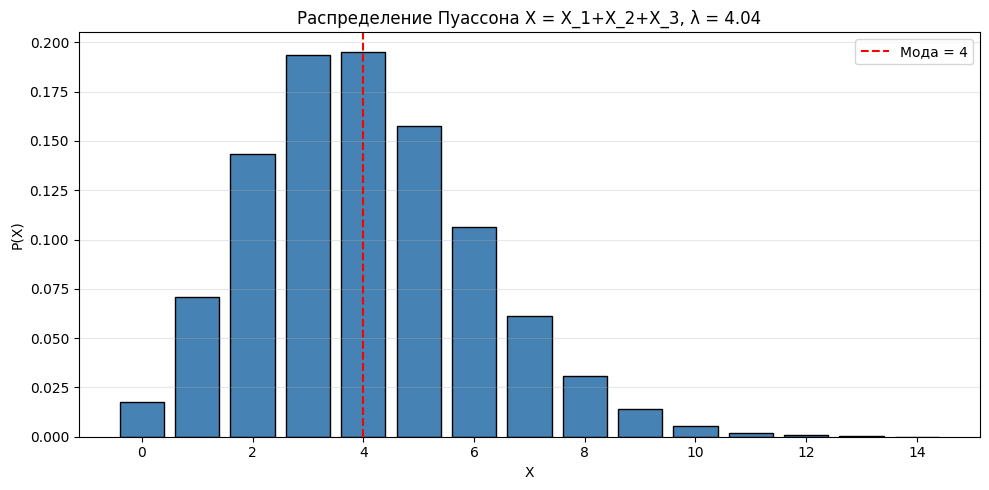

In [17]:
lam1, lam2, lam3 = 0.8**2, 1.8**2, 0.4**2
lam = lam1 + lam2 + lam3
print(f'λ_1 = {lam1}, λ_2 = {lam2}, λ_3 = {lam3}, λ = {lam}')

# 1) P(X = 7)
P_7 = poisson.pmf(7, lam)
print(f'1) P(X=7) = {P_7:.4f}')

# 2) Наиболее вероятное значение (мода)
mode = int(np.floor(lam))
print(f'2) Мода = {mode} (P = {poisson.pmf(mode, lam):.4f})')

# 3) σ_X = sqrt(λ)
sigma_X = np.sqrt(lam)
print(f'3) σ_X = {sigma_X:.4f}')

# 4) Асимметрия Пуассона
As = 1 / np.sqrt(lam)
print(f'4) As(X) = {As:.4f}')

# 5) Эксцесс Пуассона
Ex = 1 / lam
print(f'5) Ex(X) = {Ex:.4f}')

# Моделирование
N = 500000
X = np.random.poisson(lam1, N) + np.random.poisson(lam2, N) + np.random.poisson(lam3, N)
print(f'\nМоделирование:')
print(f'P_hat(X=7) = {np.mean(X == 7):.4f}')
print(f'Мода (сим) = {np.bincount(X).argmax()}')
print(f'sigma_hat = {X.std():.4f}')
print(f'As_hat = {((X - X.mean())**3).mean() / X.std()**3:.4f}')
print(f'Ex_hat = {((X - X.mean())**4).mean() / X.std()**4 - 3:.4f}')

# График распределения
ks = np.arange(0, 15)
plt.figure(figsize=(10, 5))
plt.bar(ks, poisson.pmf(ks, lam), color='steelblue', edgecolor='black')
plt.axvline(x=mode, color='red', ls='--', label=f'Мода = {mode}')
plt.xlabel('X'); plt.ylabel('P(X)')
plt.title(f'Распределение Пуассона X = X_1+X_2+X_3, λ = {lam}')
plt.legend(); plt.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()
